# Skill by lead, exceedance persistence and interpretation (RQ2, RQ3)

Models at 1, 3, 5, 10 and 14 days, ERA5 and new-event skill, exceedance persistence, standardised coefficients, drop-one-group test, case studies of the three strongest events, and the raw-label robustness check.

**Thesis:** Sections 4.4–4.8 · Tables 4.4–4.6, 4.8, 4.9, A.2, A.3 · Figs. 4.9–4.11 · Appendix C.7, C.8  
**Input:** predictor_table_1982_2025.csv, features_det_t+7.csv  
**Output:** wp2_*, wp5_*, rob1_raw_hierarchy.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

P4-1 (v2) — Evaluation framework (replaces the old P4-1)

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import os, json, time, numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
OOF  = f'{PROC}/oof'; os.makedirs(OOF, exist_ok=True)
H = 7
groups = json.load(open(f'{PROC}/feature_groups.json'))
T = {k: pd.read_csv(f'{PROC}/features_{k}_t+{H}.csv', index_col=0, parse_dates=True) for k in ('det', 'raw')}
YEARS = sorted(T['det'].year.unique())

def train_mask(tab, test_years):
    """Drop test years, rows whose t+7 target is in a test year (purge), first 30 days after a test year (embargo)."""
    m = ~tab.year.isin(test_years) & ~tab.target_year.isin(test_years)
    after = tab.year.isin([y + 1 for y in test_years]) & (tab.index.dayofyear <= 30)
    return m & ~after

def mcc_from(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, dtype=float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

def best_threshold(y, p):
    th = np.unique(np.r_[np.arange(0.02, 0.99, 0.01), p])       # includes the calibrated step values
    th = th[(th > 0) & (th < 1)]
    P = p[None, :] >= th[:, None]
    tp = (P & (y == 1)).sum(1); fp = (P & (y == 0)).sum(1)
    fn = ((~P) & (y == 1)).sum(1); tn = ((~P) & (y == 0)).sum(1)
    m = mcc_from(tp, fp, fn, tn)
    return th[np.argmax(m)], m.max()

def loyo(kind, grid, cols, name, inner_folds=4, verbose=True):
    """Leave-one-year-out. Inside each training fold only:
    1) inner year-grouped CV picks the hyper-parameters (max MCC),
    2) isotonic calibration is fitted on the inner out-of-fold probabilities,
    3) the threshold is chosen on the calibrated out-of-fold probabilities.
    grid = list of (label, model_factory)."""
    tab, rows, t0 = T[kind], [], time.time()
    for y in YEARS:
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        chunks = np.array_split(np.array(sorted(tr.year.unique())), inner_folds)
        best = None
        for lab, make in grid:
            oof = pd.Series(np.nan, index=tr.index)
            for ch in chunks:
                itr, iva = tr[train_mask(tr, list(ch))], tr[tr.year.isin(ch)]
                oof.loc[iva.index] = make().fit(itr[cols], itr.y).predict_proba(iva[cols])[:, 1]
            ok = oof.notna()
            score = best_threshold(tr.y[ok].values, oof[ok].values)[1]
            if best is None or score > best[0]: best = (score, lab, make, oof[ok], tr.y[ok])
        _, lab, make, oof, yo = best
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof.values, yo.values)
        th, _ = best_threshold(yo.values, iso.predict(oof.values))
        p = iso.predict(make().fit(tr[cols], tr.y).predict_proba(te[cols])[:, 1])
        rows.append(pd.DataFrame({'year': y, 'y': te.y.values, 'prob': p, 'pred': (p >= th).astype(int),
                                  'thr': th, 'params': lab}, index=te.index))
    out = pd.concat(rows); out.to_csv(f'{OOF}/{name}_{kind}.csv')
    if verbose: print(f'{name} [{kind}] done in {time.time() - t0:.0f}s | params chosen: '
                      f'{out.groupby("year").params.first().value_counts().to_dict()}')
    return out

def persistence(kind):
    """Honest persistence: MHW state knowable on day t (SST above threshold >= 5 consecutive days)."""
    tab = T[kind]; p = tab.mhw_causal.astype(float)
    out = pd.DataFrame({'year': tab.year, 'y': tab.y, 'prob': p, 'pred': p.astype(int), 'thr': 0.5}, index=tab.index)
    out.to_csv(f'{OOF}/persistence_{kind}.csv'); return out

def climatology(kind):
    """Brier-score reference only: P(MHW) by calendar month from the training years; no yes/no forecast."""
    tab, rows = T[kind], []
    for y in YEARS:
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        pm = tr.y.groupby(tr.index.month).mean()
        rows.append(pd.DataFrame({'year': y, 'y': te.y.values, 'prob': pm.reindex(te.index.month).values,
                                  'pred': np.nan, 'thr': np.nan}, index=te.index))
    out = pd.concat(rows); out.to_csv(f'{OOF}/climatology_{kind}.csv'); return out

def onset_rows(o):
    """Forecast days whose target day t+7 is the first day of an MHW event."""
    prev = o.y.shift(1); consecutive = (o.index.to_series().diff().dt.days == 1).values
    return (o.y == 1) & (prev == 0) & consecutive

def metrics(o, clim):
    y, p = o.y.values, o.prob.values
    r = {'PR_AUC': average_precision_score(y, p) if y.any() else np.nan,
         'BSS': 1 - np.mean((p - y) ** 2) / np.mean((clim.prob.reindex(o.index).values - y) ** 2)}
    if o.pred.notna().all():
        pr = o.pred.values.astype(int)
        tp = int(((pr == 1) & (y == 1)).sum()); fp = int(((pr == 1) & (y == 0)).sum())
        fn = int(((pr == 0) & (y == 1)).sum()); tn = int(((pr == 0) & (y == 0)).sum())
        on = onset_rows(o)
        r.update(MCC=float(mcc_from(tp, fp, fn, tn)), F1=2 * tp / max(2 * tp + fp + fn, 1),
                 CSI=tp / max(tp + fp + fn, 1), onset_hit=float(o.pred[on].mean()), n_onsets=int(on.sum()),
                 TP=tp, FP=fp, FN=fn, TN=tn)
    return r

def year_counts(o):
    g = o.assign(tp=(o.pred == 1) & (o.y == 1), fp=(o.pred == 1) & (o.y == 0),
                 fn=(o.pred == 0) & (o.y == 1), tn=(o.pred == 0) & (o.y == 0)).groupby('year')
    return g[['tp', 'fp', 'fn', 'tn']].sum().reindex(YEARS).values

def bootstrap(o, refs, B=2000, seed=0):
    """Resample whole years (same resamples for every model): MCC CI and paired MCC-gain CI vs each reference."""
    idx = np.random.default_rng(seed).integers(0, len(YEARS), (B, len(YEARS)))
    m = mcc_from(*year_counts(o)[idx].sum(1).T)
    out = {'MCC_lo': np.percentile(m, 2.5), 'MCC_hi': np.percentile(m, 97.5)}
    for rn, ro in refs.items():
        d = m - mcc_from(*year_counts(ro)[idx].sum(1).T)
        out[f'gain_vs_{rn}_lo'], out[f'gain_vs_{rn}_hi'] = np.percentile(d, 2.5), np.percentile(d, 97.5)
    return out

def report(results, refs=('persistence', 'logit_sst'), years=None):
    """refs: honest persistence (plan rule) and the SST-only model (research question)."""
    rows = {}
    clim = results['climatology'] if years is None else results['climatology'][results['climatology'].year.isin(years)]
    for name, o in results.items():
        oo = o if years is None else o[o.year.isin(years)]
        r = metrics(oo, clim)
        if years is None and name != 'climatology':
            r.update(bootstrap(oo, {rn: results[rn] for rn in refs if rn in results and rn != name}))
        rows[name] = r
    return pd.DataFrame(rows).T

Mounted at /content/drive


p5-0

In [ ]:
OOF = f'{PROC}/oof_p5'; os.makedirs(OOF, exist_ok=True)

def best_threshold(y, p):
    """Threshold with the highest MCC. Candidates: a 0.01 grid plus the distinct calibrated values
    (or 300 upper quantiles when the probabilities are continuous)."""
    u = np.unique(p)
    extra = u if len(u) <= 500 else np.quantile(p, np.linspace(0.5, 1, 301))
    th = np.unique(np.r_[np.arange(0.01, 1.0, 0.01), extra])
    th = th[(th > 0) & (th < 1)]
    P = p[None, :] >= th[:, None]
    tp = (P & (y == 1)).sum(1); fp = (P & (y == 0)).sum(1)
    fn = ((~P) & (y == 1)).sum(1); tn = ((~P) & (y == 0)).sum(1)
    m = mcc_from(tp, fp, fn, tn)
    return th[np.argmax(m)], m.max()

p5-1 (definations only)

In [ ]:
# ================= P5-1 (definitions only — no training loop) =================
import os, numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

class XGBW:
    """XGBoost with class weighting computed from each training set (scale_pos_weight = negatives / positives)."""
    def __init__(self, **kw): self.kw = kw
    def fit(self, X, y):
        spw = float((y == 0).sum()) / max(float((y == 1).sum()), 1.0)
        self.m = XGBClassifier(scale_pos_weight=spw, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                               tree_method='hist', n_jobs=-1, random_state=0, eval_metric='logloss', **self.kw)
        self.m.fit(X, y); return self
    def predict_proba(self, X): return self.m.predict_proba(X)

logit = lambda C: (lambda: make_pipeline(StandardScaler(),
                        LogisticRegression(C=C, class_weight='balanced', max_iter=3000)))
rf = lambda leaf: (lambda: RandomForestClassifier(n_estimators=150, max_features='sqrt', min_samples_leaf=leaf, max_samples=0.5,
                                                  class_weight='balanced_subsample', n_jobs=-1, random_state=0))
xgb = lambda d: (lambda: XGBW(max_depth=d, learning_rate=0.05, n_estimators=300))
GRIDS = {'logit': [(f'C={C}', logit(C)) for C in (0.01, 0.1, 1.0)],
         'rf':    [(f'leaf={l}', rf(l)) for l in (10, 50)],
         'xgb':   [(f'depth={d}', xgb(d)) for d in (3, 5)]}
FSETS = {'sst':  groups['sst'] + groups['calendar'],
         'era5': groups['sst'] + groups['calendar'] + groups['era5'],
         'all':  groups['sst'] + groups['calendar'] + groups['era5'] + groups['indices']}

def run(kind, model, fset):
    """Resumable: a finished run is read back from the OOF folder instead of being recomputed."""
    name = f'{model}_{fset}'
    f = f'{OOF}/{name}_{kind}.csv'
    if os.path.exists(f):
        return pd.read_csv(f, index_col=0, parse_dates=True)
    return loyo(kind, GRIDS[model], FSETS[fset], name, inner_folds=4 if model == 'logit' else 3)

print('P5-1 definitions loaded')

P5-1 definitions loaded


wp2-1

In [ ]:
# ================= WP2-1  skill at leads 1, 3, 5, 10, 14 days (resumable; ~40 min per lead) =================
import os, inspect, numpy as np, pandas as pd, matplotlib.pyplot as plt
assert len(inspect.signature(year_counts).parameters) == 1, \
    'WP1 cells overwrote year_counts/mcc_from: restart, run P4-1 v2, P5-0, P5-1 definitions, then this cell'
FIG = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)

LEADS2 = [1, 3, 5, 10, 14]
MODELS = [('logit', 'sst'), ('logit', 'era5'), ('rf', 'sst'), ('rf', 'era5')]
feat = pd.read_csv(f'{PROC}/features_det_t+7.csv', index_col=0, parse_dates=True).drop(columns=['y', 'target_year'])
lab_det = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True).mhw_detrended

def table_for(h):
    """Same features on day t (built only from days <= t); target = detrended MHW label on day t+h."""
    y = lab_det.shift(-h).reindex(feat.index)
    tb = feat.assign(y=y, target_year=(feat.index + pd.Timedelta(days=h)).year).dropna(subset=['y'])
    tb['y'] = tb.y.astype(int)
    return tb

RES = {}
for h in LEADS2:
    OOF = f'{PROC}/oof_lead{h}'; os.makedirs(OOF, exist_ok=True)      # loyo/persistence/climatology write here
    T = {'det': table_for(h)}
    print(f'--- lead {h} d: {len(T["det"])} rows, MHW share {T["det"].y.mean():.1%}')
    R = {'persistence': persistence('det'), 'climatology': climatology('det')}
    for m, s in MODELS:
        R[f'{m}_{s}'] = run('det', m, s)
    RES[h] = R

# lead 7 = the Phase 5 runs (identical code), read back from file
RES[7] = {n: pd.read_csv(f'{PROC}/oof_p5/{n}_det.csv', index_col=0, parse_dates=True)
          for n in ['persistence', 'climatology'] + [f'{m}_{s}' for m, s in MODELS]}

--- lead 1 d: 16035 rows, MHW share 7.4%
--- lead 3 d: 16035 rows, MHW share 7.4%
--- lead 5 d: 16035 rows, MHW share 7.4%
--- lead 10 d: 16032 rows, MHW share 7.4%
--- lead 14 d: 16028 rows, MHW share 7.4%


WP2-2 & WP3

In [ ]:
# ================= WP2-2 / WP3  skill-by-lead table: occurrence skill and new-event skill =================
LALL = sorted(RES)
idx = np.random.default_rng(0).integers(0, len(YEARS), (2000, len(YEARS)))
ci = lambda d: f'{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}'
quiet_all = feat.mhw_causal == 0                                    # no MHW knowable on day t
rows = []
for h in LALL:
    R = RES[h]
    names = [n for n in R if n != 'climatology']
    bm  = {n: mcc_from(*year_counts(R[n])[idx].sum(1).T) for n in names}
    sub = {n: R[n][quiet_all.reindex(R[n].index).fillna(False).values] for n in names if n != 'persistence'}
    bq  = {n: mcc_from(*year_counts(o)[idx].sum(1).T) for n, o in sub.items()}
    for n in names:
        r = metrics(R[n], R['climatology'])
        row = {'lead': h, 'model': n, 'MCC': round(r['MCC'], 3),
               'MCC 95% CI': f'{np.percentile(bm[n], 2.5):.3f} to {np.percentile(bm[n], 97.5):.3f}',
               'MCC_lo': np.percentile(bm[n], 2.5), 'MCC_hi': np.percentile(bm[n], 97.5),
               'BSS': round(r['BSS'], 3), 'onset hit': round(r['onset_hit'], 3)}
        if n != 'persistence':
            m, s = n.split('_')
            o = sub[n]; y, p = o.y.values, o.pred.values.astype(int)
            row['gain vs persistence'] = ci(bm[n] - bm['persistence'])
            row['new-event MCC'] = round(float(mcc_from(((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum(),
                                                         ((p == 0) & (y == 1)).sum(), ((p == 0) & (y == 0)).sum())), 3)
            if s == 'era5':
                row['ERA5 gain (MCC)'] = ci(bm[n] - bm[f'{m}_sst'])
                row['ERA5 gain (new-event MCC)'] = ci(bq[n] - bq[f'{m}_sst'])
        rows.append(row)
SK = pd.DataFrame(rows); SK.to_csv(f'{PROC}/wp2_skill_by_lead_det.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
for h in LALL:
    print(f'\n===== lead {h} d =====')
    print(SK[SK.lead == h].drop(columns=['lead', 'MCC_lo', 'MCC_hi']).set_index('model').fillna('').to_string())


===== lead 1 d =====
               MCC      MCC 95% CI    BSS  onset hit gain vs persistence new-event MCC   ERA5 gain (MCC) ERA5 gain (new-event MCC)
model                                                                                                                             
persistence  0.625  0.570 to 0.664  0.361      0.000                                                                              
logit_sst    0.783  0.747 to 0.810  0.679      0.000    +0.129 to +0.194         0.659                                            
logit_era5   0.779  0.740 to 0.813  0.688      0.028    +0.126 to +0.189         0.661  -0.024 to +0.014          -0.025 to +0.029
rf_sst       0.782  0.745 to 0.811  0.688      0.000    +0.131 to +0.192         0.655                                            
rf_era5      0.777  0.739 to 0.807  0.678      0.000    +0.124 to +0.184         0.653  -0.019 to +0.007          -0.024 to +0.016

===== lead 3 d =====
               MCC      MCC 95% CI    B

WP2 & WP3

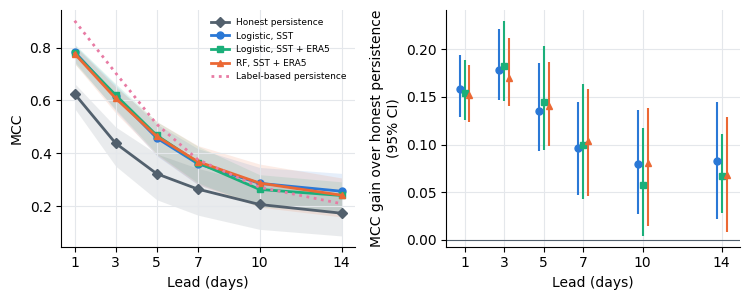

In [ ]:
# ================= WP2-3  figure: skill vs lead with both persistence benchmarks =================
lp = pd.read_csv(f'{PROC}/wp1_leakage_curve_bob.csv'); lp = lp[lp.target == 'det'].set_index('lead')
fig, (a, b) = plt.subplots(1, 2, figsize=(7.6, 3.1))
sty = {'persistence': ('#52606d', 'D', 'Honest persistence'), 'logit_sst': ('#2a78d6', 'o', 'Logistic, SST'),
       'logit_era5': ('#1baf7a', 's', 'Logistic, SST + ERA5'), 'rf_era5': ('#eb6834', '^', 'RF, SST + ERA5')}
for n, (c, mk, lb) in sty.items():
    g = SK[SK.model == n].sort_values('lead')
    a.fill_between(g.lead, g.MCC_lo, g.MCC_hi, color=c, alpha=0.12, lw=0)
    a.plot(g.lead, g.MCC, marker=mk, color=c, lw=2, ms=5, label=lb)
a.plot(lp.index, lp.MCC_label, ':', color='#e87ba4', lw=2, label='Label-based persistence')
a.set_xlabel('Lead (days)'); a.set_ylabel('MCC'); a.set_xticks(LALL); a.legend(fontsize=6.5, frameon=False)
for n, (c, mk, lb) in sty.items():
    if n == 'persistence': continue
    g = SK[SK.model == n].sort_values('lead')
    d = g['gain vs persistence'].str.split(' to ', expand=True).astype(float)
    mid = g.MCC.values - SK[SK.model == 'persistence'].sort_values('lead').MCC.values
    b.errorbar(g.lead + {'logit_sst': -0.25, 'logit_era5': 0, 'rf_era5': 0.25}[n], mid,
               yerr=[mid - d[0].values, d[1].values - mid], fmt=mk, color=c, ms=5, capsize=0, lw=1.5, label=lb)
b.axhline(0, color='#52606d', lw=0.8); b.set_xticks(LALL); b.set_xlabel('Lead (days)')
b.set_ylabel('MCC gain over honest persistence\n(95% CI)')
for ax in (a, b):
    ax.grid(color='#e4e7eb', lw=0.8); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
fig.tight_layout(); fig.savefig(f'{FIG}/wp2_skill_by_lead.png', dpi=300)

WP2-4: one stricter baseline (a few seconds, no training)

In [ ]:
# ================= WP2-4  diagnostic: exceedance persistence (SST above threshold on day t) =================
pt  = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
exc = (pt.sst_detrended > pt.thresh90_detrended).astype(int)
bmcc = lambda o: mcc_from(*year_counts(o)[idx].sum(1).T)
pmcc = lambda o: float(mcc_from(*year_counts(o).sum(0)))
rows = []
for h in LALL:
    R = RES[h]
    E = R['persistence'].copy(); E['pred'] = exc.reindex(E.index).values.astype(int)
    q = quiet_all.reindex(E.index).fillna(False).values
    bE, bEq = bmcc(E), bmcc(E[q])
    row = {'lead': h, 'honest persistence': round(pmcc(R['persistence']), 3),
           'exceedance persistence': round(pmcc(E), 3),
           'exc. pers. 95% CI': f'{np.percentile(bE, 2.5):.3f} to {np.percentile(bE, 97.5):.3f}',
           'exc. pers. new-event MCC': round(pmcc(E[q]), 3)}
    for n in ('logit_sst', 'rf_era5'):
        row[f'{n} gain vs exc. pers.'] = ci(bmcc(R[n]) - bE)
        row[f'{n} new-event gain vs exc. pers.'] = ci(bmcc(R[n][q]) - bEq)
    rows.append(row)
EX = pd.DataFrame(rows); EX.to_csv(f'{PROC}/wp2_exceedance_persistence_det.csv', index=False)
print(EX.set_index('lead').to_string())

      honest persistence  exceedance persistence exc. pers. 95% CI  exc. pers. new-event MCC logit_sst gain vs exc. pers. logit_sst new-event gain vs exc. pers. rf_era5 gain vs exc. pers. rf_era5 new-event gain vs exc. pers.
lead                                                                                                                                                                                                                            
1                  0.625                   0.771    0.740 to 0.798                     0.660             -0.003 to +0.024                       -0.025 to +0.019           -0.008 to +0.016                     -0.032 to +0.013
3                  0.438                   0.606    0.557 to 0.645                     0.521             -0.001 to +0.018                       -0.015 to +0.020           -0.009 to +0.013                     -0.015 to +0.017
5                  0.323                   0.441    0.371 to 0.495                     0.353        

WP5-1

In [ ]:
# ================= WP5-1  what the SST-only model uses: standardized logistic coefficients by lead =================
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
COLS = FSETS['sst']
LEADS_ALL = [1, 3, 5, 7, 10, 14]
rng = np.random.default_rng(0)
coef, sig = {}, {}
for h in LEADS_ALL:
    tb = table_for(h).dropna(subset=COLS)
    X, y, yr = tb[COLS].values, tb.y.values, tb.index.year.values
    fit = lambda i: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000)
                                  ).fit(X[i], y[i])[-1].coef_[0]
    pos = {u: np.where(yr == u)[0] for u in np.unique(yr)}
    ys = list(pos)
    coef[h] = fit(np.arange(len(y)))
    boot = np.array([fit(np.concatenate([pos[u] for u in rng.choice(ys, len(ys))])) for _ in range(200)])
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    sig[h] = (lo > 0) | (hi < 0)
    print(f'lead {h} d done')

CO = pd.DataFrame(coef, index=COLS); SG = pd.DataFrame(sig, index=COLS)
CO.to_csv(f'{PROC}/wp5_logit_sst_coefficients.csv'); SG.to_csv(f'{PROC}/wp5_logit_sst_coef_significant.csv')
show = CO.round(2).astype(str) + np.where(SG, '*', ' ')
print('\nStandardized coefficients (* = 95% bootstrap CI excludes 0), sorted by |coef| at 7 d')
print(show.loc[CO[7].abs().sort_values(ascending=False).index].to_string())

lead 1 d done
lead 3 d done
lead 5 d done
lead 7 d done
lead 10 d done
lead 14 d done

Standardized coefficients (* = 95% bootstrap CI excludes 0), sorted by |coef| at 7 d
                   1       3       5       7       10      14
sst_dist_thr    1.48*  -0.01   -0.58   -0.97   -1.15*  -1.03 
sst_anom_rm30   0.41*   0.52*    0.6*   0.68*   0.81*   0.91*
sst_anom_rm3    1.11*   0.65*    0.6*   0.51*   0.44*   0.17 
sst_anom_chg1   0.92*   0.73*   0.67*   0.44*   0.31*   0.21*
sst_anom        0.65*   0.43*   0.46*   0.44*   0.43*   0.33 
sst_anom_max7   0.17   -0.03    0.07    0.41    0.79*   0.72*
doy_cos        -0.24*  -0.29*  -0.31*  -0.33*  -0.34*  -0.33*
sst_anom_lag3   0.51*   0.22*   0.35*   0.31*    0.3*   0.24 
sst_anom_lag1   0.38*   0.21    0.26    0.31*   0.33*   0.27 
sst_anom_rm7    0.12    0.52    0.01    -0.3   -0.64*  -0.32 
sst_anom_chg7   0.21*   0.28*   0.28*    0.3*   0.22*   0.21*
sst_anom_chg3   0.23*   0.33*   0.17*   0.21*    0.2*   0.15 
sst_anom_lag7   0.46* 

WP5-1b

In [ ]:
# ================= WP5-1b  which time scale carries the skill: drop-one-group test (logit_sst, same honest LOYO) =================
GRP = {'current state': ['sst_anom', 'sst_dist_thr', 'sst_anom_lag1', 'sst_anom_lag3', 'sst_anom_rm3',
                         'exceed_now', 'exceed_run', 'mhw_causal'],
       'tendency':      ['sst_anom_chg1', 'sst_anom_chg3', 'sst_anom_chg7'],
       'background':    ['sst_anom_lag7', 'sst_anom_rm7', 'sst_anom_rm14', 'sst_anom_rm30', 'sst_anom_max7', 'sst_anom_sd7'],
       'season':        ['doy_sin', 'doy_cos']}
assert sorted(sum(GRP.values(), [])) == sorted(FSETS['sst']), 'groups must cover the SST-model features exactly'

DROP = {}
for h in LALL:
    OOF = f'{PROC}/oof_lead{h}'; os.makedirs(OOF, exist_ok=True)
    T = {'det': table_for(h)}
    for g, gcols in GRP.items():
        name = f'logit_sst_no_{g.replace(" ", "_")}'
        f = f'{OOF}/{name}_det.csv'
        DROP[(h, g)] = (pd.read_csv(f, index_col=0, parse_dates=True) if os.path.exists(f) else
                        loyo('det', GRIDS['logit'], [c for c in FSETS['sst'] if c not in gcols], name, inner_folds=4))

bmcc = lambda o: mcc_from(*year_counts(o)[idx].sum(1).T)
pmcc = lambda o: float(mcc_from(*year_counts(o).sum(0)))
qmask = lambda o: quiet_all.reindex(o.index).fillna(False).values
rows = []
for h in LALL:
    full = RES[h]['logit_sst']
    bF, bFq = bmcc(full), bmcc(full[qmask(full)])
    for g in GRP:
        d = DROP[(h, g)]
        loss, lossq = bF - bmcc(d), bFq - bmcc(d[qmask(d)])
        rows.append({'lead': h, 'group dropped': g, 'MCC full': round(pmcc(full), 3), 'MCC without': round(pmcc(d), 3),
                     'MCC loss 95% CI': ci(loss), 'sig': '*' if np.percentile(loss, 2.5) > 0 else '',
                     'new-event MCC loss 95% CI': ci(lossq), 'sig new-event': '*' if np.percentile(lossq, 2.5) > 0 else ''})
DG = pd.DataFrame(rows); DG.to_csv(f'{PROC}/wp5_drop_group_det.csv', index=False)
for g in GRP:
    print(f'\n===== dropped: {g} =====')
    print(DG[DG['group dropped'] == g].drop(columns='group dropped').set_index('lead').to_string())


===== dropped: current state =====
      MCC full  MCC without   MCC loss 95% CI sig new-event MCC loss 95% CI sig new-event
lead                                                                                     
1        0.783        0.764  +0.005 to +0.032   *          -0.005 to +0.032              
3        0.616        0.605  +0.001 to +0.021   *          -0.008 to +0.023              
5        0.458        0.463  -0.015 to +0.007              -0.017 to +0.011              
7        0.361        0.365  -0.018 to +0.009              -0.025 to +0.010              
10       0.287        0.288  -0.026 to +0.025              -0.012 to +0.041              
14       0.257        0.261  -0.015 to +0.007              -0.017 to +0.009              

===== dropped: tendency =====
      MCC full  MCC without   MCC loss 95% CI sig new-event MCC loss 95% CI sig new-event
lead                                                                                     
1        0.783        0.784  -0.0

WP5-2

Selected events (3 largest cumulative intensity, 1982-2025):
       onset        end  duration_d  cum_intensity_Cdays
0 1982-09-19 1982-11-07          50                 51.3
1 1987-11-16 1988-01-30          76                 75.0
2 2020-06-25 2020-08-13          50                 38.9

===== lead 7 d =====
                                    first event day caught (days after onset)  event days forecast (%)  false alarms, 30 d before onset
event onset forecast                                                                                                                   
1982-09-19  logistic (SST)                                                  6                       84                                2
            exceedance persistence                                          7                       80                                1
            honest persistence                                             11                       64                                0
1987-11-1

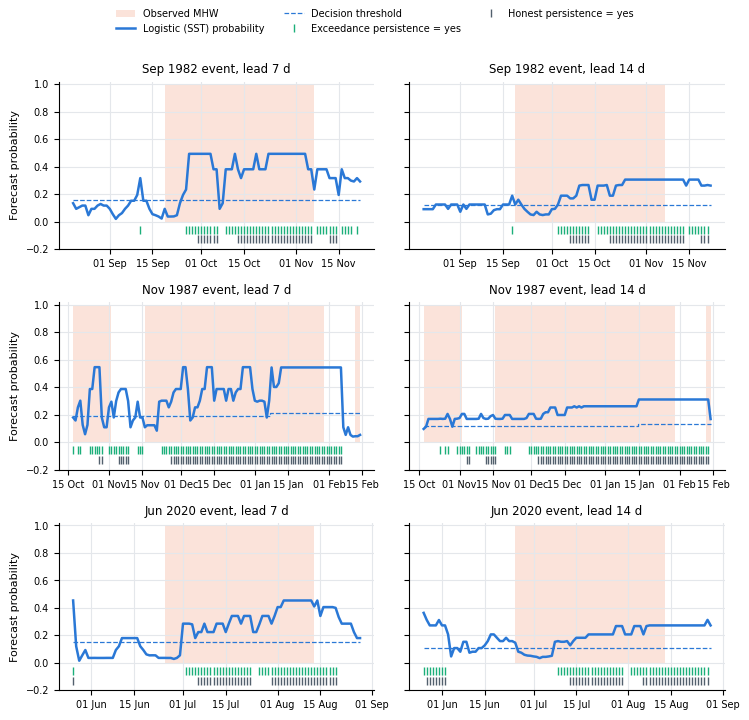

In [ ]:
# ================= WP5-2  case studies: the 3 strongest MHWs (rule fixed before looking at the forecasts) =================
import matplotlib.dates as mdates
lab = lab_det.astype(int)
pt  = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
exc = (pt.sst_detrended > pt.thresh90_detrended).astype(int)

# 1) events and selection rule: largest cumulative intensity (sum of SST anomaly over event days, Hobday 2016)
b = lab.values.astype(int); d = np.diff(np.r_[0, b, 0])
st, en = np.where(d == 1)[0], np.where(d == -1)[0] - 1
anom = feat.sst_anom.reindex(lab.index)
EV = pd.DataFrame({'onset': lab.index[st], 'end': lab.index[en], 'duration_d': en - st + 1,
                   'cum_intensity_Cdays': [anom.iloc[s:e + 1].sum() for s, e in zip(st, en)]})
TOP = EV.sort_values('cum_intensity_Cdays', ascending=False).head(3).sort_values('onset').reset_index(drop=True)
print('Selected events (3 largest cumulative intensity, 1982-2025):'); print(TOP.round(1).to_string()); print()

# 2) forecasts placed on their TARGET date (issue date + lead)
def at_target(s, h):
    s = s.copy(); s.index = s.index + pd.Timedelta(days=h); return s
FC = {}
for h in (7, 14):
    m = RES[h]['logit_sst']
    FC[h] = {'prob': at_target(m.prob, h), 'thr': at_target(m.thr, h),
             'logistic (SST)': at_target(m.pred, h),
             'exceedance persistence': at_target(exc.reindex(m.index), h),
             'honest persistence': at_target(RES[h]['persistence'].pred, h)}

# 3) per-event scores
day = pd.Timedelta(days=1)
rows = []
for _, ev in TOP.iterrows():
    evd = pd.date_range(ev.onset, ev.end)
    pre = pd.date_range(ev.onset - 30 * day, ev.onset - day)
    quiet_pre = pre[lab.reindex(pre).fillna(1).values == 0]          # observed non-MHW days before onset
    for h in (7, 14):
        for n in ('logistic (SST)', 'exceedance persistence', 'honest persistence'):
            s_ev = FC[h][n].reindex(evd).fillna(0)
            first = s_ev[s_ev == 1].index.min()
            rows.append({'event onset': f'{ev.onset:%Y-%m-%d}', 'lead': h, 'forecast': n,
                         'first event day caught (days after onset)': (first - ev.onset).days if pd.notna(first) else 'never',
                         'event days forecast (%)': int(round(100 * s_ev.mean())),
                         'false alarms, 30 d before onset': int(FC[h][n].reindex(quiet_pre).fillna(0).sum())})
CS = pd.DataFrame(rows); CS.to_csv(f'{PROC}/wp5_case_studies.csv', index=False)
for h in (7, 14):
    print(f'===== lead {h} d ====='); print(CS[CS.lead == h].drop(columns='lead').set_index(['event onset', 'forecast']).to_string()); print()

# 4) figure: 3 events x 2 leads
fig, axs = plt.subplots(3, 2, figsize=(7.6, 7.2), sharey=True)
for i, ev in TOP.iterrows():
    win = pd.date_range(ev.onset - 30 * day, ev.end + 15 * day)
    obs = lab.reindex(win).fillna(0).values
    for j, h in enumerate((7, 14)):
        ax = axs[i, j]
        ax.fill_between(win, 0, 1, where=obs == 1, color='#eb6834', alpha=0.18, lw=0, step='mid', label='Observed MHW')
        ax.plot(win, FC[h]['prob'].reindex(win), color='#2a78d6', lw=1.8, label='Logistic (SST) probability')
        ax.step(win, FC[h]['thr'].reindex(win), where='mid', color='#2a78d6', ls='--', lw=0.9, label='Decision threshold')
        for k, (n, c) in enumerate((('exceedance persistence', '#1baf7a'), ('honest persistence', '#52606d'))):
            yes = (FC[h][n].reindex(win).fillna(0) == 1).values
            ax.plot(win[yes], np.full(yes.sum(), -0.06 - 0.07 * k), '|', color=c, ms=6, label=n.capitalize() + ' = yes')
        ax.set_ylim(-0.2, 1.02); ax.set_title(f'{ev.onset:%b %Y} event, lead {h} d', fontsize=8.5)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); ax.tick_params(labelsize=7)
        ax.grid(color='#e4e7eb', lw=0.8); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
    axs[i, 0].set_ylabel('Forecast probability', fontsize=8)
hh, ll = axs[0, 0].get_legend_handles_labels()
fig.legend(hh, ll, loc='upper center', ncol=3, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(f'{FIG}/wp5_case_studies.png', dpi=300)

Raw sst check

In [ ]:
# ================= ROB-1  raw-label robustness: is the baseline hierarchy the same without detrending? =================
LEADS6 = [1, 3, 5, 7, 10, 14]
featR = pd.read_csv(f'{PROC}/features_raw_t+7.csv', index_col=0, parse_dates=True).drop(columns=['y', 'target_year'])
pt    = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
excR  = (pt.sst > pt.thresh90).astype(int)
RESR, rows = {}, []
for h in LEADS6:
    OOF = f'{PROC}/oof_lead{h}'; os.makedirs(OOF, exist_ok=True)
    y = pt.mhw_raw.shift(-h).reindex(featR.index)
    tb = featR.assign(y=y, target_year=(featR.index + pd.Timedelta(days=h)).year).dropna(subset=['y'])
    tb['y'] = tb.y.astype(int); T = {'raw': tb}
    R = {'persistence': persistence('raw'), 'logit_sst': run('raw', 'logit', 'sst')}
    E = R['persistence'].copy(); E['pred'] = excR.reindex(E.index).values.astype(int); R['exceedance'] = E
    RESR[h] = R
    b = {n: mcc_from(*year_counts(o)[idx].sum(1).T) for n, o in R.items()}
    p = {n: float(mcc_from(*year_counts(o).sum(0))) for n, o in R.items()}
    rows.append({'lead': h, 'honest pers.': round(p['persistence'], 3), 'exceedance pers.': round(p['exceedance'], 3),
                 'logit_sst': round(p['logit_sst'], 3),
                 'logit vs honest (95% CI)': ci(b['logit_sst'] - b['persistence']),
                 'logit vs exceedance (95% CI)': ci(b['logit_sst'] - b['exceedance'])})
RB = pd.DataFrame(rows).set_index('lead'); RB.to_csv(f'{PROC}/rob1_raw_hierarchy.csv')
print(RB.to_string())

logit_sst [raw] done in 76s | params chosen: {'C=1.0': 38, 'C=0.01': 5, 'C=0.1': 1}
logit_sst [raw] done in 73s | params chosen: {'C=0.01': 43, 'C=1.0': 1}
logit_sst [raw] done in 65s | params chosen: {'C=0.01': 44}
logit_sst [raw] done in 61s | params chosen: {'C=0.01': 44}
logit_sst [raw] done in 68s | params chosen: {'C=0.01': 44}
logit_sst [raw] done in 60s | params chosen: {'C=0.01': 44}
      honest pers.  exceedance pers.  logit_sst logit vs honest (95% CI) logit vs exceedance (95% CI)
lead                                                                                                 
1            0.680             0.808      0.815         +0.117 to +0.152             -0.003 to +0.019
3            0.501             0.650      0.660         +0.134 to +0.187             -0.005 to +0.023
5            0.383             0.503      0.518         +0.087 to +0.192             -0.012 to +0.042
7            0.318             0.396      0.444         +0.066 to +0.187             +0.006 to